In [7]:
from typing import Annotated
from typing_extensions import TypedDict
from langgraph.graph import END, START
from langgraph.graph.state import StateGraph
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition
from langchain_core.tools import tool
from langchain_core.messages import BaseMessage
import os
from dotenv import load_dotenv
load_dotenv()

True

In [8]:
os.environ["LANGSMITH_PROJECT"]="TestProject"

In [10]:
import os
os.environ["GROQ_API_KEY"]=os.getenv("GROQ_API_KEY")
os.environ["LANGSMITH_API_KEY"]=os.getenv("LANGCHAIN_API_KEY")
os.environ["LANGSMITH_TRACING"]="true"


In [11]:
from langchain.chat_models import init_chat_model
llm = init_chat_model("groq:openai/gpt-oss-20b")
llm

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.6.6', 'langchain': '1.4.3'}}, profile={'name': 'GPT OSS 20B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x12979a350>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x12979ad50>, model_name='openai/gpt-oss-20b', model_kwargs={}, groq_api_key=SecretStr('**********'))

In [12]:
class State(TypedDict):
    messages:Annotated[list[BaseMessage],add_messages]

In [13]:
## Graph With tool Call
from langchain_core.tools import tool

@tool
def add(a:float,b:float):
    """Add two number"""
    return a+b

tools=[add]
llm_with_tool=llm.bind_tools(tools)

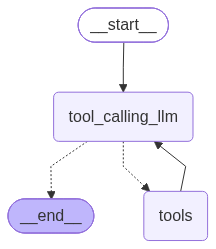

In [14]:
## Stategraph

## Node definition
def call_llm_model(state:State):
    return {"messages":[llm_with_tool.invoke(state['messages'])]}

## Grpah
builder=StateGraph(State)

builder.add_node("tool_calling_llm",call_llm_model)

tool_node=ToolNode(tools)
builder.add_node("tools",tool_node)

## Add Edges
builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    # If the latest message (result) from assistant is a tool call -> tools_condition routes to tools
    # If the latest message (result) from assistant is a not a tool call -> tools_condition routes to END
    tools_condition
)
builder.add_edge("tools","tool_calling_llm")

## compile the graph
graph=builder.compile()

from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

In [16]:
response=graph.invoke({"messages":"What is machine learning"})
response

{'messages': [HumanMessage(content='What is machine learning', additional_kwargs={}, response_metadata={}, id='b669e17e-8279-4d9c-affb-547dd4053f1f'),
  AIMessage(content='**Machine learning (ML)** is a field of computer science that builds systems capable of improving their performance on a task by learning from data, rather than being explicitly programmed for every possible scenario.\n\n---\n\n### Core Idea\n- **Data → Knowledge**: An ML model observes many examples (data points) and automatically discovers patterns or rules that explain the data.\n- **Generalization**: Once trained, the model can apply what it learned to new, unseen data.\n\n---\n\n### How It Works (in a nutshell)\n1. **Collect Data** – Gather examples that represent the problem space (e.g., images of cats and dogs, customer purchase histories, sensor readings).\n2. **Choose a Model** – Pick an algorithm that can represent the underlying pattern (e.g., decision trees, neural networks, support vector machines).\n3. 

In [18]:
response=graph.invoke({"messages":"what is 5 plus 20"})
response

{'messages': [HumanMessage(content='what is 5 plus 20', additional_kwargs={}, response_metadata={}, id='aee6c599-0af6-41fe-b1be-93f05b064afc'),
  AIMessage(content='', additional_kwargs={'reasoning_content': 'We need to use the add function.', 'tool_calls': [{'id': 'fc_a61efe28-e938-4265-99ea-c748dc6d3af4', 'function': {'arguments': '{"a":5,"b":20}', 'name': 'add'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 35, 'prompt_tokens': 127, 'total_tokens': 162, 'completion_time': 0.039175453, 'completion_tokens_details': {'reasoning_tokens': 9}, 'prompt_time': 0.006497793, 'prompt_tokens_details': None, 'queue_time': 0.315211064, 'total_time': 0.045673246}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_4a35f7bd1b', 'service_tier': 'on_demand', 'finish_reason': 'tool_calls', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a134b4-0308-70e3-8b8a-b396898aa6ab-0', tool_calls=[{'name': 'add', 'args': {'a': 5, 'b': 20}, 'id': 'fc_a61efe2

In [20]:
response["messages"][-1].content

'25.'